# [레퍼런스] 딥러닝 시계열 복습

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## 0. 레퍼런스 쓰는 법

<div style="background:#FFFFFF;color:#000000;padding:40px;border-radius:12px;border:1px solid #E6E6E6;border-left:4px solid #051C2C">
<div style="font-size:0.9em;color:#656565">AI 데이터 인텔리전스 전문가 과정 · 딥러닝 시계열</div>
<h1 style="color:#000000;margin:10px 0">딥러닝 시계열 복습</h1>
<div style="font-size:1.05em;color:#656565">복습 카드 네 장과 임계비율 카드 한 장, 모듈 결정 규칙 표</div>
</div>

팀 대항전 문항을 풀다가 근거가 필요하면 해당 카드를 찾아봅니다. 카드 1～4 는 글로벌 모델, 사전학습과 제로샷, 공변량, 분위수와 포함률 이론의 결론을 한 장씩 모은 것입니다. 카드마다 같은 차례로 적었습니다.

카드 5 의 임계비율은 앞의 네 이론에 없던 개념입니다. 마지막 구획에는 서울 지하철 100개 역의 평가표와 모듈의 결정 규칙을 모았습니다.

## 1. 글로벌 모델(1일차)

**핵심 질문** 100개 역을 모델 하나로 학습한 신경망을 다음 주 역별 예측에 쓸 수 있는가?

**글로벌 모델(global model)** 은 여러 계열을 모델 하나로 학습하는 방식입니다. 글로벌 MLP 는 역마다 원점 전날까지 28일을 입력받아 다음 7일을 한 번에 예측합니다. 규모가 다른 역은 역마다 표준화한 뒤 한 표로 모읍니다.

예측은 MASE 로 채점합니다. MASE 는 그 계열에서 계절 나이브가 평소 내던 오차의 몇 배만큼 틀렸는지를 나타냅니다. 예를 들어 가게 예시에서 직전 7일 평균은 하루 20.4명 틀렸고, 계절 나이브가 평소 내던 오차는 7.6명이었습니다. 그래서 직전 7일 평균의 MASE 는 20.4 ÷ 7.6 ≈ 2.7 입니다.

**예측 원점**은 예측하는 7일이 시작하는 날이고, 시계열 과목의 원점보다 하루 뒤입니다. 그런데 아래 그림처럼 원점 5개 가운데 세 주에 평일 공휴일이 있습니다. 그래서 평가표는 공휴일 없는 두 주와 공휴일 있는 세 주로 나눠 평균합니다.

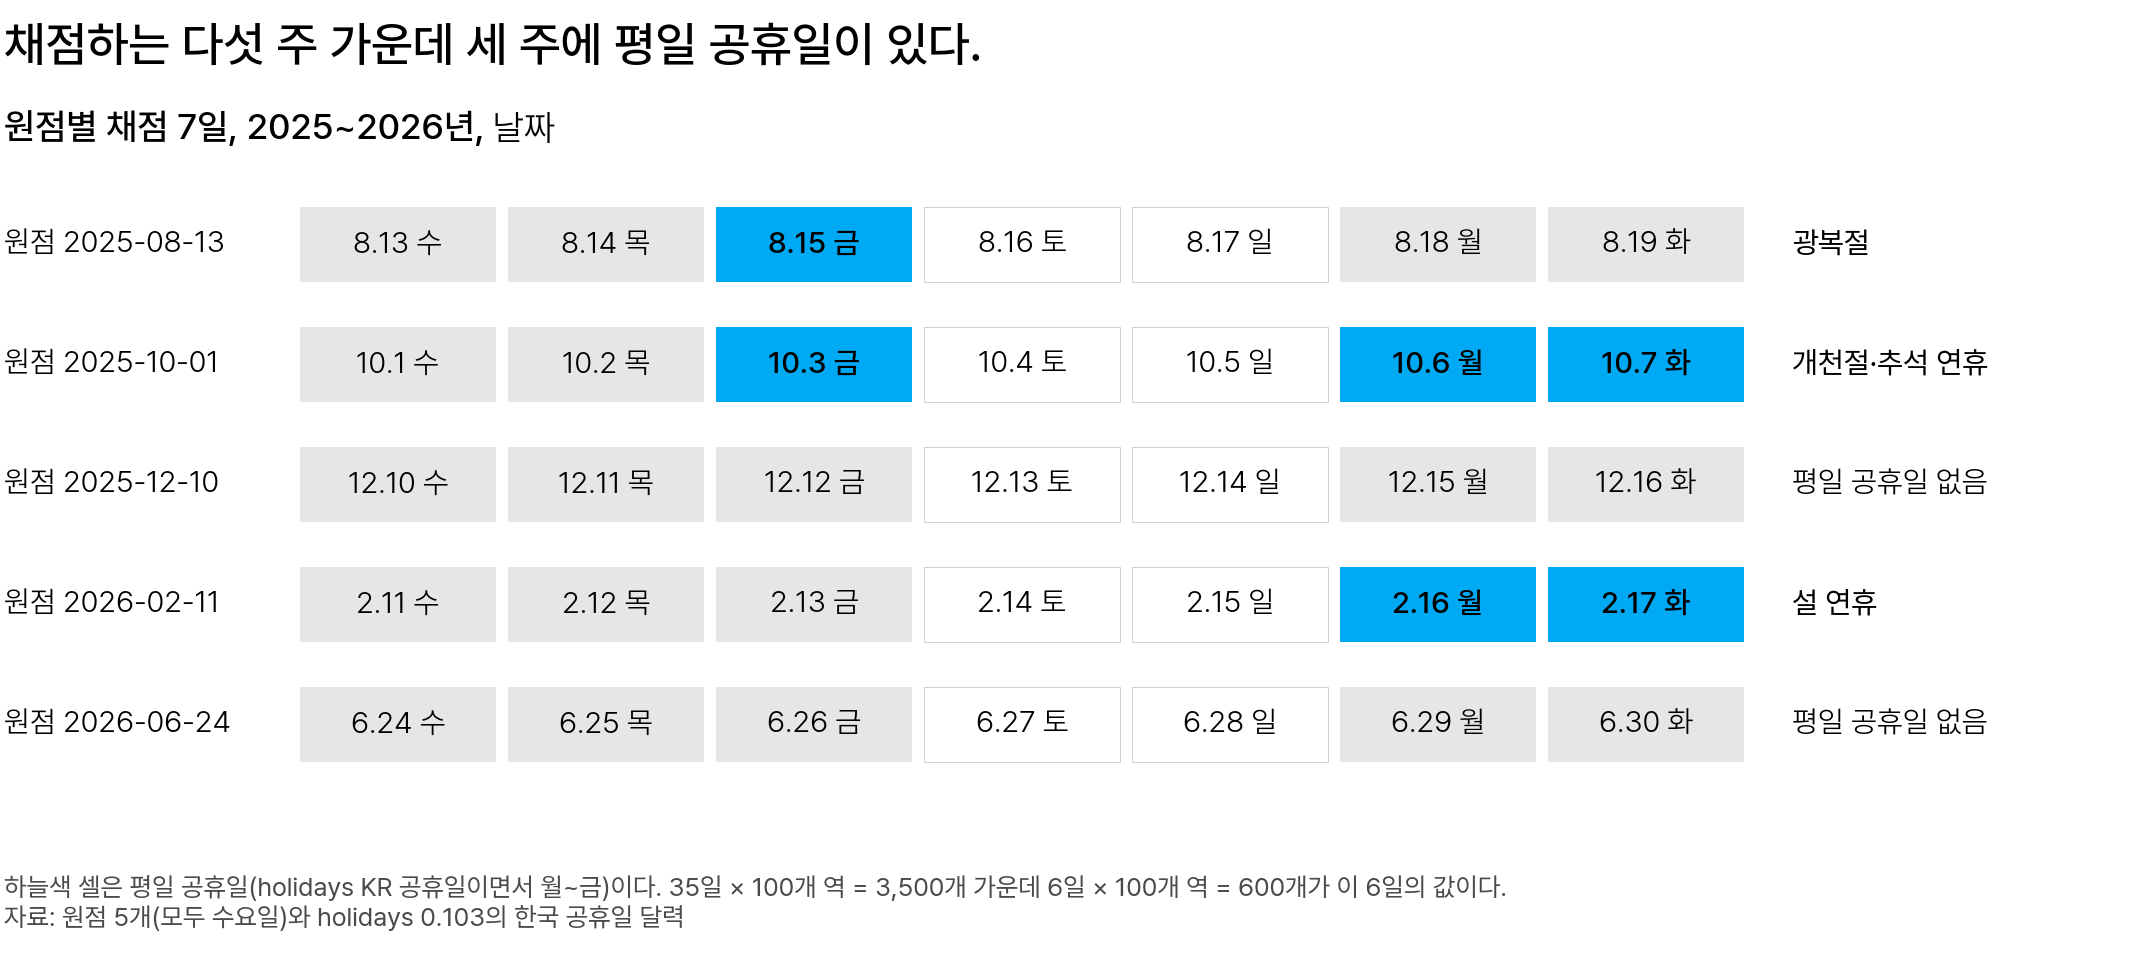

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 채점하는 다섯 주. 한 행이 원점 하나의 채점 7일이고, 하늘색 셀이 평일 공휴일 6일이다</em></p>

**결론**

- 공휴일 없는 주의 후보는 글로벌 MLP(MAE 손실)입니다. 공휴일 없는 두 주 MASE 가 0.359 로 같은 주의 계절 나이브 0.445 보다 낮고, 시드 0～4 다섯 번 모두 낮습니다.
- 손실을 MSE 로 둔 글로벌 MLP 는 쓰지 않습니다. 공휴일 없는 두 주 MASE 가 0.739 이고, 예측의 87.2% 가 실제보다 작아 인력이 모자랍니다.
- 공휴일 있는 세 주는 이 평가표로 정하지 않습니다. 공휴일 여부가 입력 28일에 없어, 두 MLP 와 계절 나이브 모두 MASE 가 2.6～2.8 입니다.

**기억할 식·지표**

$$
\text{역 단위 MASE} = \frac{1}{100}\sum_{i=1}^{100} \frac{\text{MAE}_i}{Q_i}
$$

- $\text{MAE}_i$ : 역 $i$ 에서 채점 7일의 절대 오차를 평균한 값(명)
- $Q_i$ : 원점 전날까지 계절 나이브가 역 $i$ 에서 낸 절대 오차의 평균(명)
- $i$ : 역 번호(1～100)

MASE 가 1 이면 계절 나이브가 평소 내던 오차만큼 틀린 것입니다.

$$
z = \frac{y - \mu_i}{\sigma_i}, \qquad \hat{y} = \hat{z} \times \sigma_i + \mu_i
$$

- $\mu_i$, $\sigma_i$ : 역 $i$ 의 평균과 표준편차. 원점 직전 56일은 검증 구간이라, 원점 57일 전까지의 자료로 구합니다
- $z$ : 표준화한 값. 모델이 낸 표준화 예측 $\hat{z}$ 는 명 단위 $\hat{y}$ 로 복원한 뒤 채점합니다

**쓰는 코드**

- `fit_global(origin, loss="mae")`: 원점마다 손실을 MAE 로 둔 글로벌 MLP 를 학습합니다
- `raw28 = MAT[:, o - 28:o]`: 원점 전날에서 끝나는 입력 28일입니다
- `score(MAT[:, o:o + H], pred, qden_of(origin))["mase"]`: 원점 하나의 역 단위 MASE 입니다

**흔한 실수**

- MASE 를 1 과 비교하는 실수입니다. MLP(MSE 손실)의 0.739 는 1 보다 낮지만, 같은 주의 계절 나이브보다 높습니다. 공휴일 있는 세 주에는 계절 나이브 자신이 2.767 입니다.
- 입력 28일을 원점 당일까지 자르는 실수입니다(`MAT[:, o - 27:o + 1]`). 원점 당일은 채점하는 7일에 들어가는 날이라, 그날 승차를 쓰면 누수입니다. 이 코드의 MLP(MSE 손실)은 공휴일 없는 두 주 약 2.13 이고, 고치면 약 0.739 입니다. 예측 7일이 하루 뒤로 밀려 채점 7일과 요일이 하루씩 어긋나서 점수가 나빠집니다. 그래서 누수는 점수가 아니라 입력 윈도의 날짜로 확인합니다.

**다시 볼 곳**

- 글로벌 모델 이론 「1. 예측 원점과 역 단위 MASE」
- 글로벌 모델 이론 「3. 글로벌 모델과 계열별 표준화」
- 글로벌 모델 이론 「6. 서울 지하철 100개 역에 글로벌 MLP 를 쓰면」과 위젯 window-lab

## 2. 사전학습과 제로샷(2일차)

**핵심 질문** 학습 없이 쓰는 Chronos-2 를 다음 주 역별 예측에 쓸 수 있는가?

**Chronos-2** 는 Amazon 이 다른 자료로 미리 학습해 공개한 시계열 예측 모델입니다. **제로샷(zero-shot)** 은 그 가중치를 고치지 않고, 과거 값을 입력으로만 전달해 예측을 받는 것입니다. 서울 지하철에서는 역마다 원점 전날까지 512일을 전달하고 7일을 한 번에 받습니다.

출력은 날마다 분위수 아홉 열이고, MASE 로 채점할 때는 `"0.5"` 열을 점 예측으로 씁니다. 예를 들어 가게 예시의 지난 수요일 10번을 0.5 분위수 100명으로 예측하면 평균 절대 오차가 15명입니다. 0.1 분위수의 25명, 0.9 분위수의 21명보다 작습니다.

그런데 입력에는 날짜도 공휴일 여부도 없습니다. 그래서 아래 그림처럼 평일 공휴일 6일을 여느 평일 크기로 예측했고, 100개 역 예측 합이 실제의 2.14배였습니다.

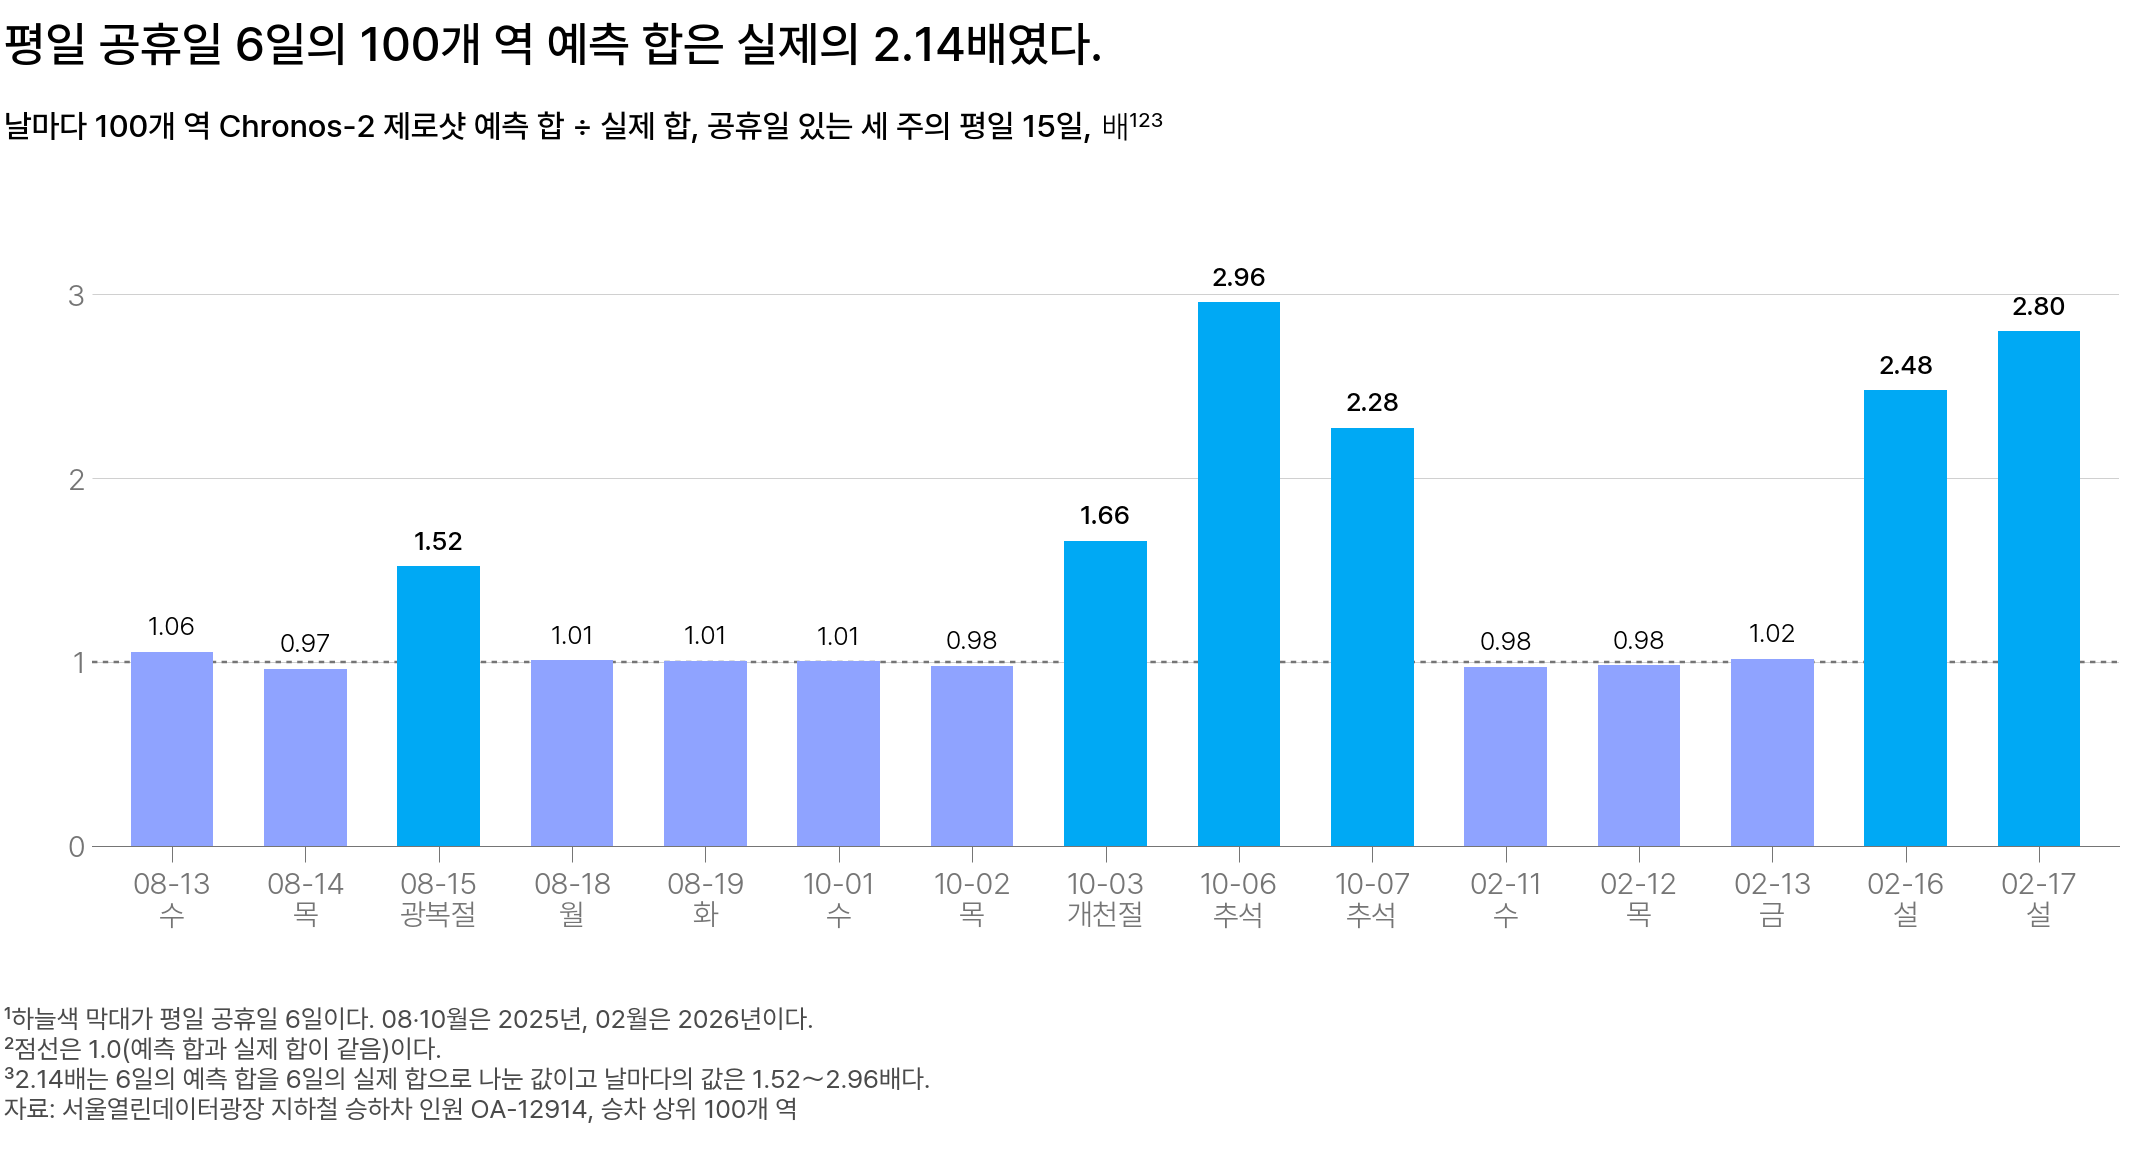

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 공휴일 있는 세 주의 평일 15일. 막대는 날마다 100개 역 Chronos-2 제로샷 예측 합 ÷ 실제 합이고, 하늘색 막대가 평일 공휴일 6일이다</em></p>

**결론**

- 공휴일 없는 주에는 제로샷도 후보입니다. 공휴일 없는 두 주 MASE 가 0.271 로 같은 주의 계절 나이브 0.445 보다 낮습니다.
- 평일 공휴일이 있는 주에는 그대로 쓰지 않습니다. 공휴일 있는 세 주 MASE 2.763 이 계절 나이브 2.767 과 거의 같습니다.
- 공개일 2025-10-17 보다 앞선 원점 둘은 사전학습 자료와 겹쳤는지 확인하지 못했다고 함께 적습니다.

**기억할 식·지표**

$$
\text{시드 범위} = 1.848 - 1.771 = 0.077
$$

- $1.848$ : 글로벌 MLP(MSE 손실)를 시드 0～4 로 다시 학습한 원점 5개 평균 MASE 가운데 가장 큰 값
- $1.771$ : 같은 다섯 값 가운데 가장 작은 값

두 방식의 평균 MASE 차이가 0.077 보다 작으면 차이가 있다고 보지 않습니다. 조금 넘는 차이는 시드 다섯 값이 모두 한쪽인지 함께 확인합니다.

**계절 나이브보다 MASE 가 낮은 역 비율**은 원점 하나에서 새 모델의 MASE 가 더 낮은 역의 비율입니다. 평균으로 정할 수 없을 때 원점마다 적습니다. 제로샷은 원점 차례로 34 · 82 · 89 · 12 · 93% 였습니다.

**쓰는 코드**

- `PIPE = BaseChronosPipeline.from_pretrained("amazon/chronos-2", device_map=DEVICE, torch_dtype=torch.float32)`: 사전학습 가중치를 불러옵니다
- `PIPE.predict_df(long_df, prediction_length=H, quantile_levels=QS, context_length=CTX, freq="D")`: `item_id` · `timestamp` · `target` 세 열의 표로 7일을 한 번에 예측합니다
- `fc["0.5"]`: 점 예측으로 쓰는 열입니다. `predictions` 열은 이름만 보고 쓰지 않습니다

**흔한 실수**

- 날마다 전날 실제값을 받아 다시 예측한 점수를 평가표에 적는 실수입니다. 원점 뒤 실측이 입력에 있어 원점 5개 평균 MASE 가 1.485 로 낮게 나옵니다. 7일을 한 번에 예측한 값은 1.766 입니다.
- 원점 5개의 역 비율을 한데 모으는 실수입니다. (34 + 82 + 89 + 12 + 93) ÷ 5 = 62% 는 공휴일 없는 주의 89% · 93% 와 설 연휴가 있는 주의 12% 를 섞은 값입니다.

**다시 볼 곳**

- 사전학습과 제로샷 이론 「3. Chronos-2 의 입력과 출력」
- 사전학습과 제로샷 이론 「4. 서울 지하철 100개 역에 Chronos-2 를 쓰면」
- 사전학습과 제로샷 이론 「5. 평일 공휴일 과대 예측」

## 3. 공변량(3일차)

**핵심 질문** 공휴일 정보를 Chronos-2 에 함께 입력하면 예측이 좋아지는가?

**공변량(covariate)** 은 예측하려는 값과 함께 모델에 입력하는 다른 열입니다. 열마다 예측 시점에 예측할 날의 값을 이미 알고 있는지를 확인합니다. 알면 **미래 공변량**이고, 아래 그림의 휴일 여부처럼 다음 주 7일의 값까지 입력합니다. 모르면 **과거 공변량**이고, 예측 시점 전날까지의 값만 씁니다.

예를 들어 가게 예시에서 과거 손님 수만 입력하면 휴일인 다음 수요일도 93.8명으로 예측합니다. 휴일 여부가 닮은 주를 더 크게 반영하는 가중 평균으로 계산하면 54.3명으로 낮아지고, 실제는 20명입니다.

Chronos-2 에는 공휴일 열을 과거 표 `df` 와 미래 입력 `future_df` 에 모두 포함해 전달합니다. Chronos-2 는 두 표에 모두 있는 열을 미래 공변량으로, 과거 표에만 있는 열을 과거 공변량으로 받습니다. 평가표에서는 이 예측을 **Chronos-2 + 공휴일** 이라고 부릅니다.

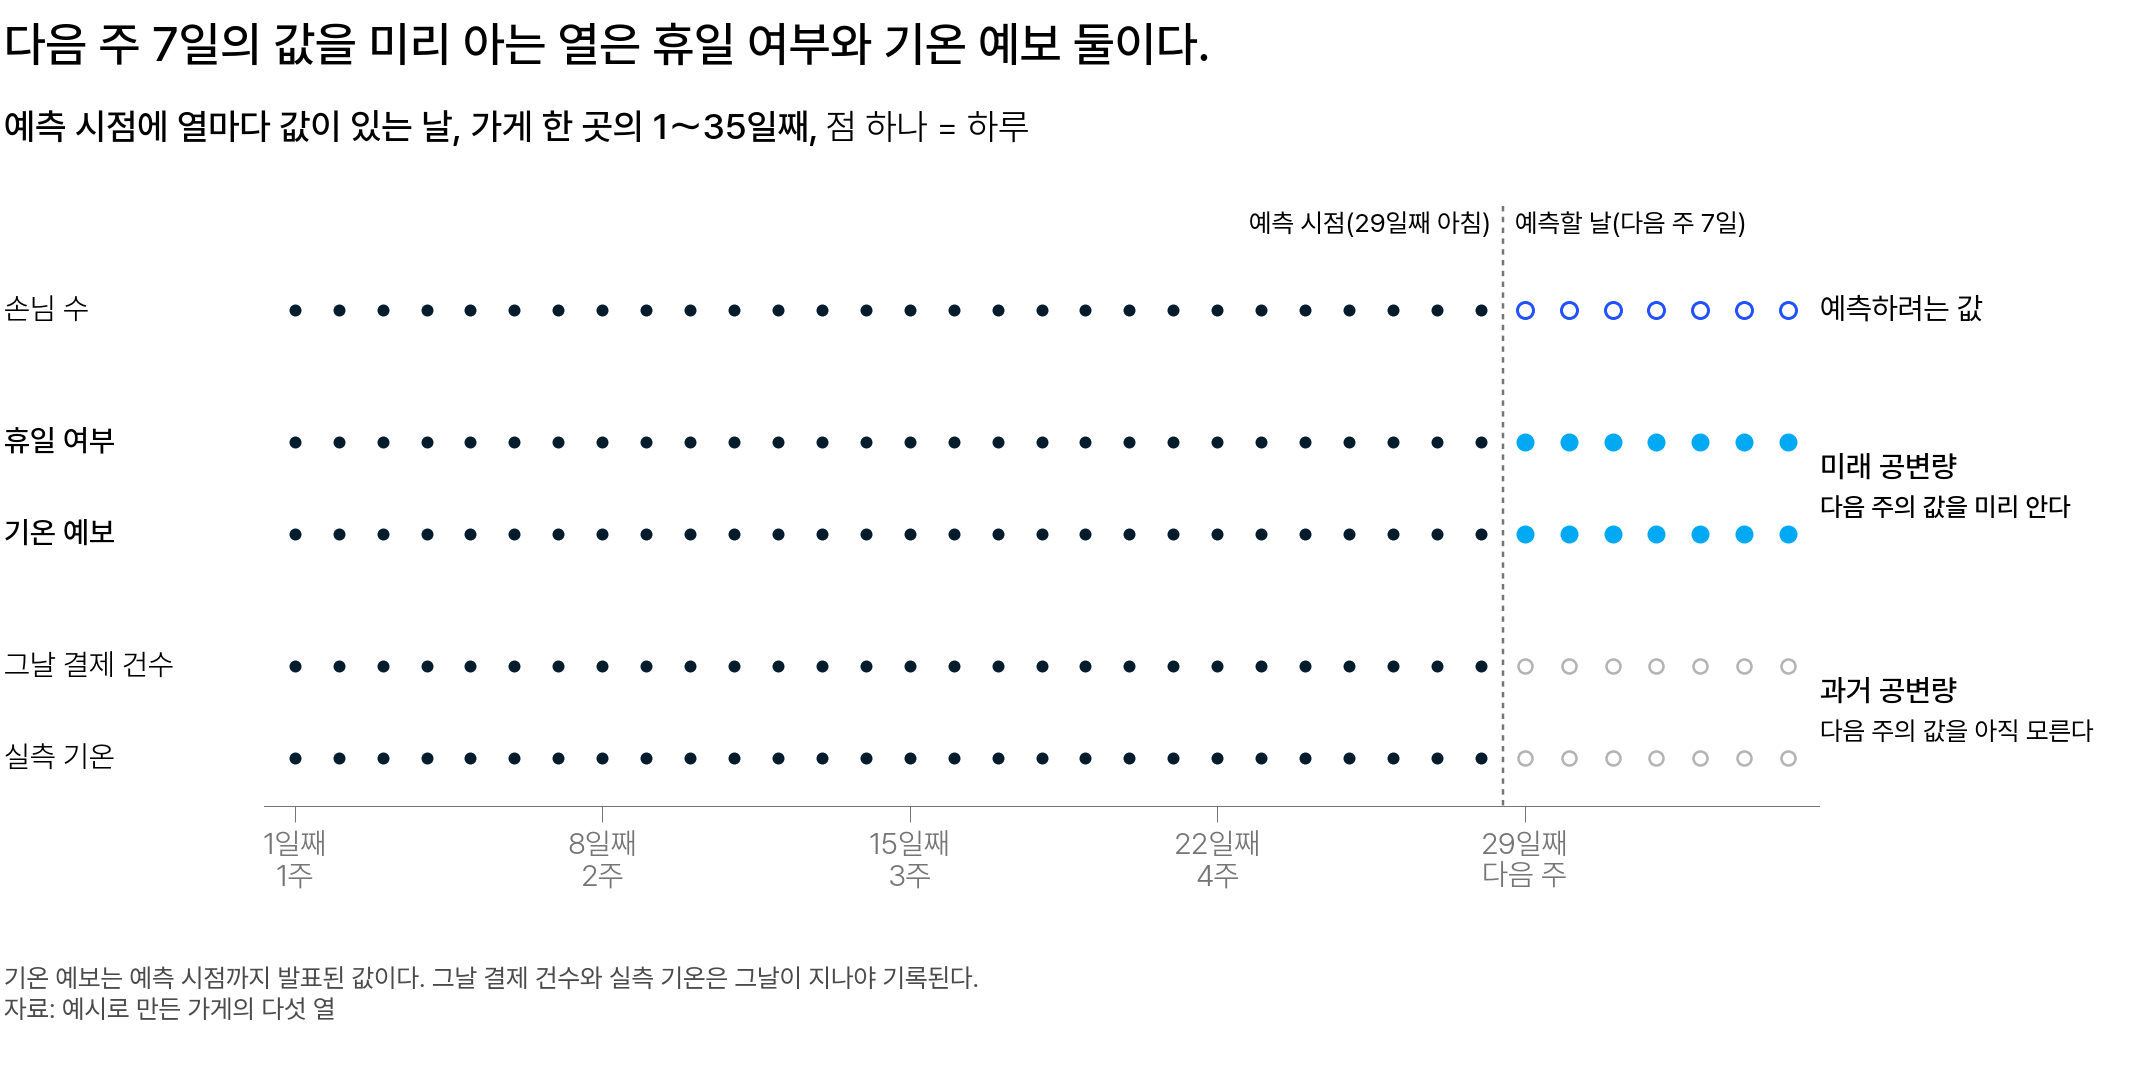

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 세로 점선이 예측 시점(29일째 아침)이다. 휴일 여부와 기온 예보만 다음 주 7일까지 값이 있다</em></p>

**결론**

- 평일 공휴일이 있는 주에는 Chronos-2 + 공휴일을 씁니다. 공휴일 있는 세 주 MASE 가 2.763 에서 1.022 로 낮아졌습니다. 설 연휴 평일 이틀만 보정한 예측값으로 바꿉니다.
- 채점 7일의 하차 인원을 미래 입력에 포함한 백테스트는 쓰지 않습니다. 공휴일 있는 세 주의 0.342 는 예측 시점에 알 수 없는 값으로 얻은 데이터 누수입니다.
- 공휴일 없는 주에도 Chronos-2 + 공휴일을 기본값으로 씁니다. 제로샷과의 차이 0.051 은 시드 범위 0.077 보다 작아, 어느 모델이 더 낫다고 하지 않습니다.

**기억할 식·지표**

$$
\text{보정한 예측값} = y_{t-7} \times r_t
$$

- $y_{t-7}$ : 1주 전 같은 요일 승차 인원. 예측 시점에 이미 아는 가장 최근의 같은 요일 값이고, 계절 나이브의 예측값과 같습니다
- $r_t$ : 지난해 같은 날의 비. 그 역의 지난해 그날 승차 인원을 같은 요일 평균으로 나눈 값입니다. 지난해 같은 날은 지난해 설날 전날과 설날입니다. 설은 해마다 날짜가 달라 날짜가 같은 날을 쓰지 않습니다

강남역 설날이면 95,750 × 0.142 ≈ 13,597명이고, 실제 승차 인원은 14,973명입니다. 공휴일 열은 값이 0 과 1 뿐이라 설 연휴와 하루 쉬는 공휴일이 구별되지 않습니다. 그래서 설 연휴 이틀만 이 식으로 바꿉니다.

**쓰는 코드**

- `df, future_df = chronos_frames(origin, holiday=True)`: 공휴일 열이 있는 과거 표와 미래 입력을 만듭니다
- `PIPE.predict_df(df, future_df=future_df, prediction_length=H, quantile_levels=QS)`: 미래 입력과 함께 예측합니다
- `list(future_df.columns)`: 예측 전에 미래 입력의 열 목록을 확인합니다. `target` 열과 하차 열이 없어야 합니다

**흔한 실수**

- 공휴일 열을 과거 표에만 포함하고 미래 입력을 빠뜨리는 실수입니다. 오류는 나지 않지만 예측할 7일의 공휴일이 전달되지 않습니다. 공휴일 있는 세 주 MASE 가 2.756 으로 제로샷과 거의 같습니다.
- 표 하나를 원점 앞뒤로 잘라 `future_df` 에 하차 열 `alight` 가 남는 실수입니다. 오류 없이 점수만 좋아집니다. 고치면 공휴일 없는 두 주 0.322, 공휴일 있는 세 주 1.022 입니다.
- 보정한 예측값에 1주 전 같은 요일 승차 인원 대신 올해의 같은 요일 평균을 곱하는 실수입니다. 올해 평균은 뒤 두 주의 승차 인원이 있어야 구하는 값이라, 예측 시점에는 없습니다.

**다시 볼 곳**

- 공변량 이론 「1. 공변량 세 종류와 누수」
- 공변량 이론 「3. 서울 지하철 100개 역 결과」
- 공변량 이론의 위젯 holiday-lab

## 4. 분위수와 포함률(4일차)

**핵심 질문** Chronos-2 + 공휴일의 80% 구간을 인력 계획에 그대로 써도 되는가?

**분위수(quantile)** 는 실제가 그 값 이하일 확률로 정한 값입니다. **80% 구간**은 0.1 분위수와 0.9 분위수 사이, 곧 예측 표의 `"0.1"` 열과 `"0.9"` 열 사이입니다. 구간을 정할 때의 목표 비율 80% 를 **명목 포함률(nominal coverage)** 이라 하고, 줄여서 명목 80% 라고 씁니다.

실제가 구간 안에 있던 날의 비율이 **포함률(empirical coverage)** 입니다. 예를 들어 가게 예시의 80～120명 구간은 새 수요일 10번 가운데 8번이 안이라 포함률이 80% 였습니다. 휴일이 3번 있는 10번에서는 60% 였고, 아래로 벗어난 3번이 모두 휴일이었습니다.

서울 지하철에서는 역 하나의 하루가 점 하나이고, 원점 하나에 700점입니다. 아래 그림의 하늘색 점이 평일 공휴일 당일이고, 6일의 600점 가운데 279점만 구간 안이었습니다.

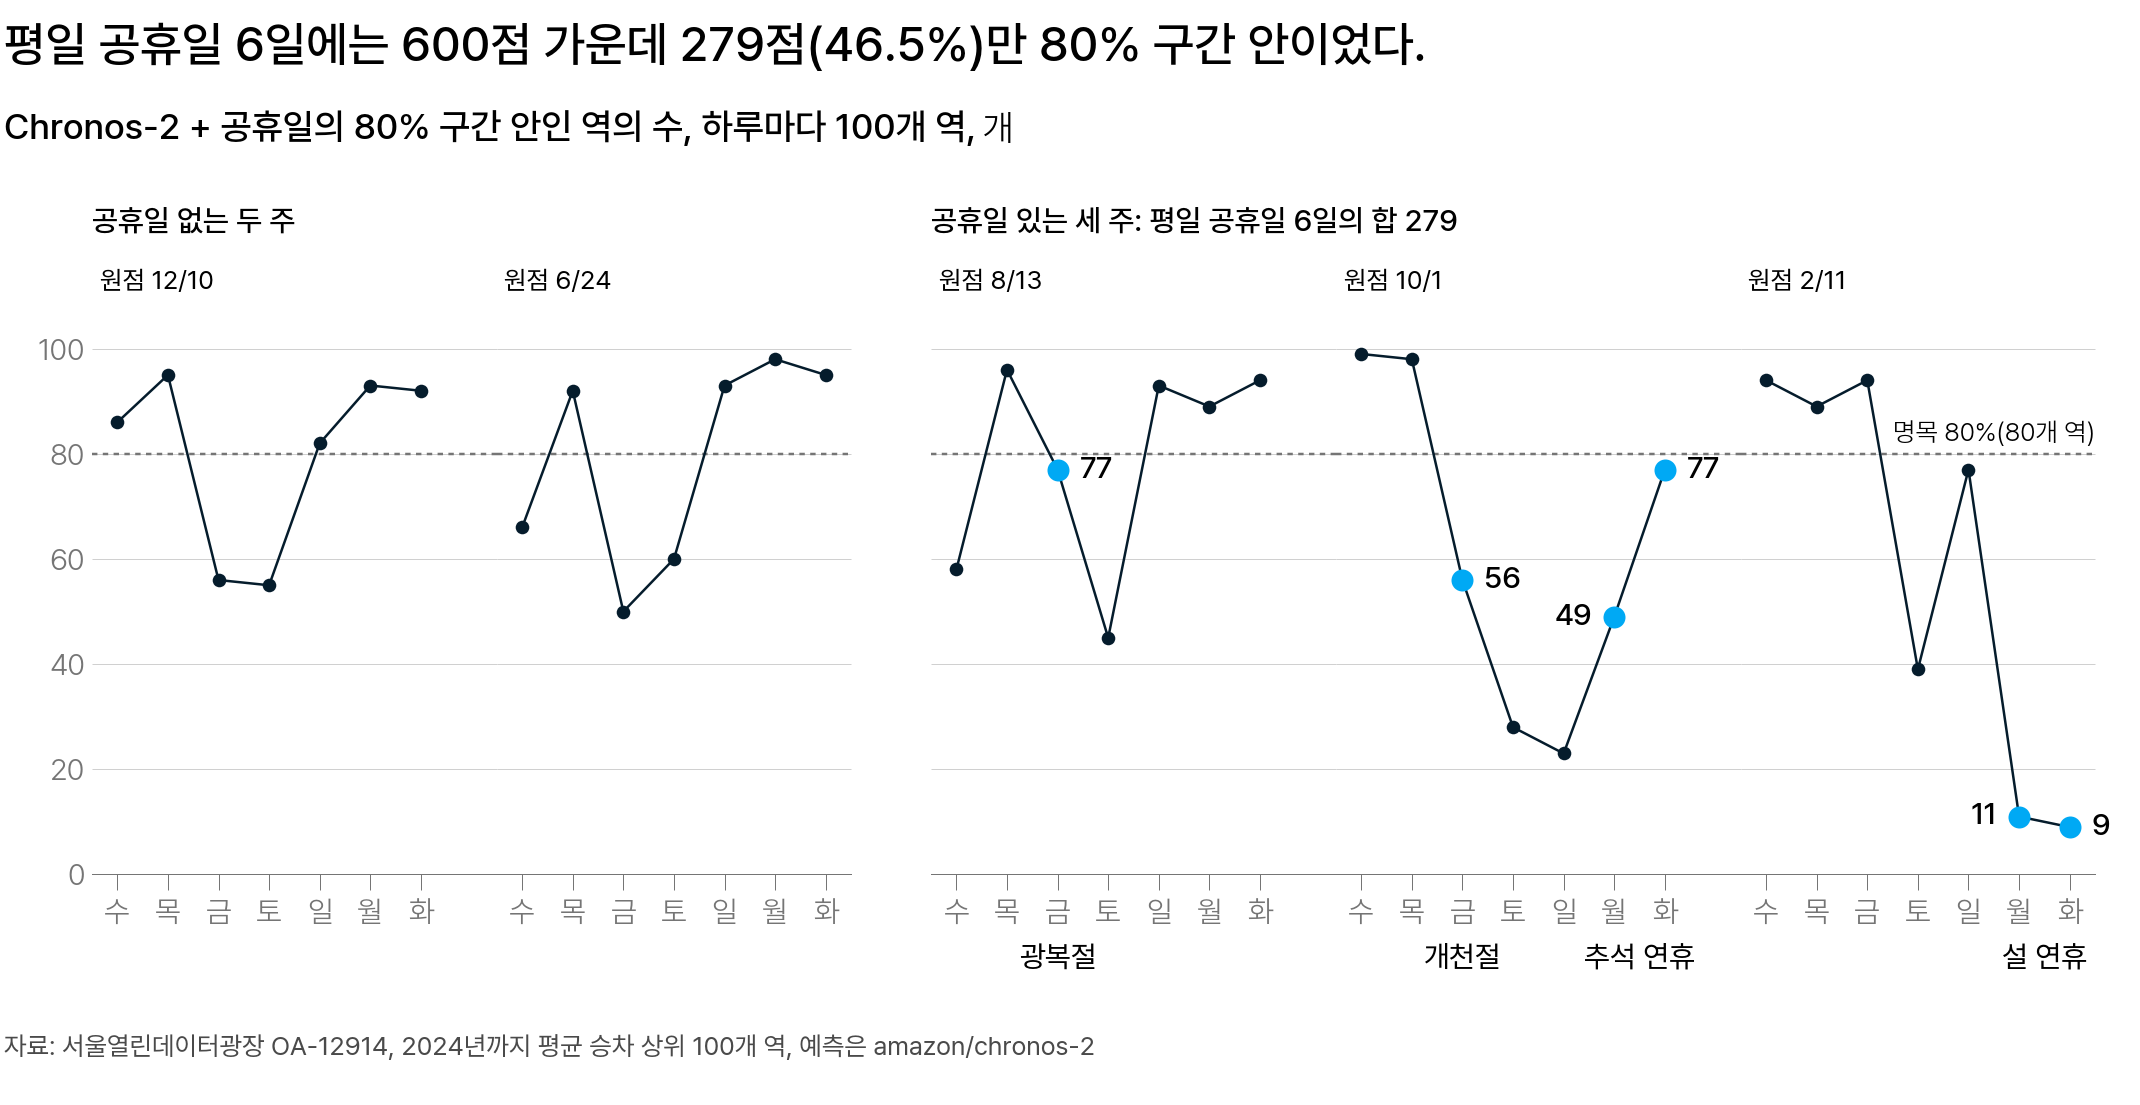

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 하루마다 80% 구간 안이던 역의 수. 하늘색 여섯 점이 평일 공휴일 당일이고, 설 연휴 이틀은 100개 역 가운데 11개 · 9개 역만 구간 안이었다</em></p>

**결론**

- 공휴일 없는 주에는 80% 구간을 그대로 씁니다. 포함률이 79.5% 로 명목 80% 에 가깝고, 위 끝보다 많은 점 18.9% 를 함께 전달합니다.
- 평일 공휴일 당일의 인력은 구간으로 정하지 않습니다. 당일 600점의 포함률이 46.5% 였습니다.
- 평일 공휴일이 있는 주의 나머지 날에는 당일을 뺀 날의 포함률 74.4% 를 구간과 함께 전달합니다. 평가표에는 두 모델을 같은 점으로 비교하도록 세 주 전체의 66.4% 를 적습니다.

**기억할 식·지표**

$$
\text{포함률} = \frac{\text{구간 안인 점의 수}}{\text{점의 수}}, \qquad \text{구간 길이} = q_{0.9} - q_{0.1}
$$

- $q_{0.9}$ : 위 끝, 곧 `"0.9"` 열의 값
- $q_{0.1}$ : 아래 끝, 곧 `"0.1"` 열의 값
- 점: 역 하나의 하루(역·날). 원점 하나에 100개 역 × 7일 = 700점입니다

포함률은 명목 80% 와 비교합니다. 구간을 넓히기만 해도 포함률이 높아지므로 평균 구간 길이와 함께 봅니다. 평균 MASE 에 쓰는 시드 범위는 포함률 비교에 쓰지 않습니다.

**쓰는 코드**

- `((fc["y"] >= fc["0.1"]) & (fc["y"] <= fc["0.9"])).mean()`: 원점 하나의 포함률입니다
- `(q[..., -1] - q[..., 0]).mean()`: 평균 구간 길이입니다. `q` 의 마지막 차원이 `"0.1"` 열부터 `"0.9"` 열까지입니다
- `(fc["y"] > fc["0.9"]).mean()`: 위 끝보다 많은 점의 비율입니다

**흔한 실수**

- 원점 5개를 합친 포함률 71.7% 하나로 전달하는 실수입니다. 공휴일 없는 두 주의 79.5% 와 공휴일 있는 세 주의 66.4% 가 한 값에 섞입니다.
- 구간을 넓혀 높아진 포함률을 좋은 구간으로 보는 실수입니다. 원점 2026-06-24 에서 제로샷은 포함률이 88.0% 로 더 높았습니다. 그런데 평균 구간 길이도 3,462명으로 Chronos-2 + 공휴일의 2,918명보다 깁니다.

**다시 볼 곳**

- 분위수와 포함률 이론 「2. 포함률과 구간 길이」
- 분위수와 포함률 이론 「3. 서울 지하철 100개 역의 포함률」
- 분위수와 포함률 이론의 위젯 coverage-lab

## 5. 임계비율

**핵심 질문** 다음 주 역별 인력은 예측 표의 분위수 아홉 열 가운데 어느 열로 정하는가?

80% 구간을 배울 때는 인력을 위 끝인 `"0.9"` 열에 맞춘다고 가정했습니다. 어느 열에 맞출지는 인력이 모자랄 때와 남을 때의 두 비용으로 정합니다.

**준비량**은 그날 손님 몇 명을 받을 만큼 준비할지 정한 값입니다. 지난 수요일 10번의 손님 수는 80 · 85 · 90 · 95 · 100 · 105 · 110 · 115 · 120 · 150명입니다. 모자란 1명분은 4만 원, 남는 1명분은 1만 원이라고 하겠습니다.

| 준비량 | 모자란 양의 합 | 남는 양의 합 | 비용 합 |
|---|---:|---:|---:|
| 0.5 분위수 100명분 | 100명분 | 50명분 | 4 × 100 + 1 × 50 = 450만 원 |
| 0.8 분위수 115명분 | 40명분 | 140명분 | 4 × 40 + 1 × 140 = 300만 원 |

115명분이면 비용 합이 100명분보다 150만 원 적습니다. 까닭은 1명분을 더 준비할 때의 변화로 알 수 있습니다. 손님이 준비량보다 많은 날마다 모자람이 1명분 줄어 4만 원이 줄어듭니다. 나머지 날마다 1명분이 남아 1만 원이 늘어납니다.

100명분에서는 두 경우가 5번씩이라 20만 원이 줄고 5만 원이 늘어, 더 준비할수록 비용 합이 줄어듭니다. 115명분부터 120명분까지는 모자란 날 2번 × 4만 원과 남는 날 8번 × 1만 원이 8만 원으로 같습니다. 그래서 더 준비해도 비용 합이 줄지 않고, 아래 그림처럼 120명분도 300만 원입니다.

115명분에서는 손님 수가 준비량 이하인 날이 10번 가운데 8번, 곧 5번 가운데 4번입니다. 즉, 이 준비량이 0.8 분위수입니다.

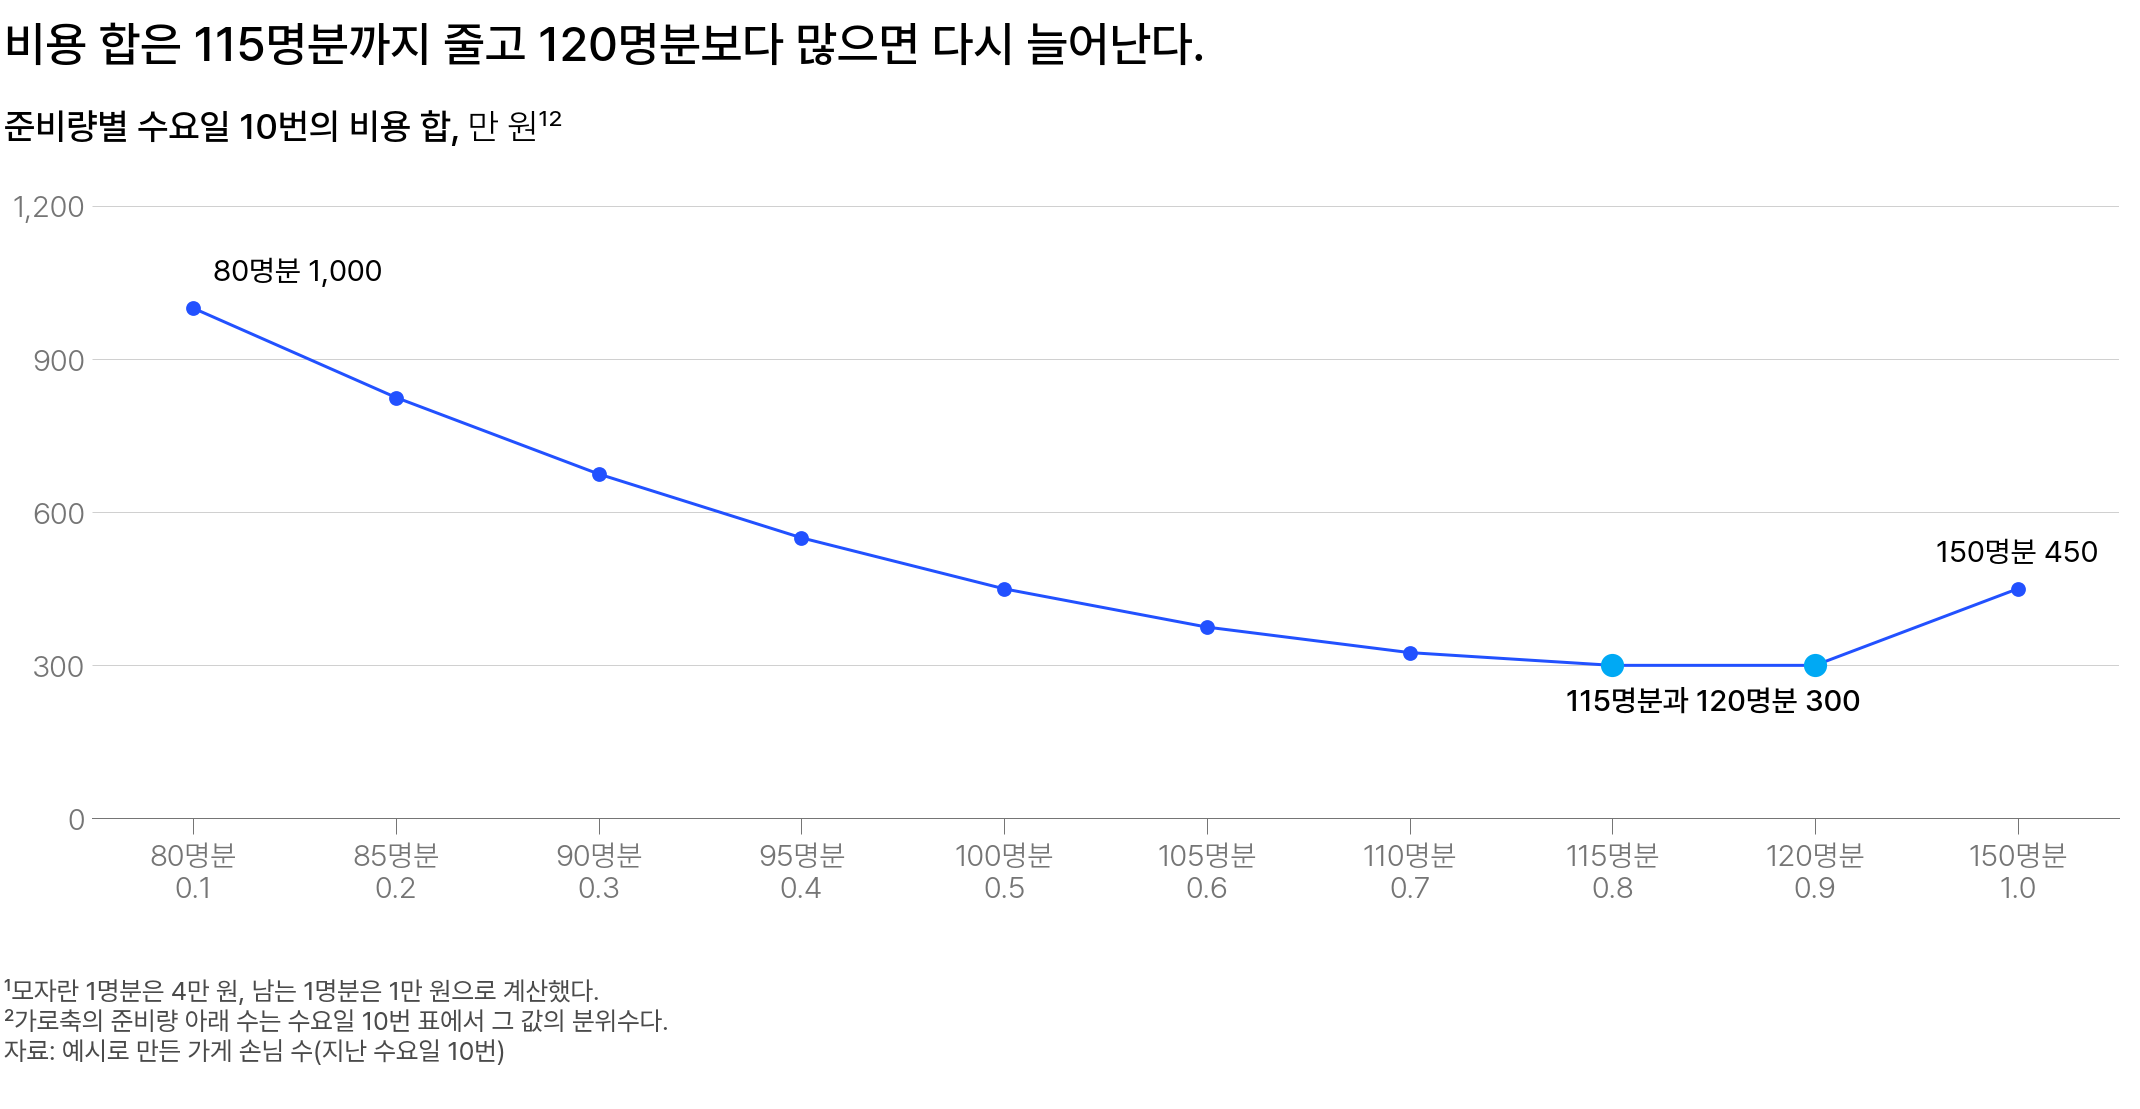

In [ ]:
# 도해 생성 코드는 LMS 에서만 실행됩니다

<p align="center"><em>▲ 준비량마다 계산한 지난 수요일 10번의 비용 합. 115명분과 120명분에서 300만 원으로 가장 낮고, 더 많이 준비하면 다시 늘어난다</em></p>

**임계비율(critical ratio)** 은 모자란 1명분의 비용을 두 비용의 합으로 나눈 값이고, 준비할 분위수입니다. 가게 예시는 4 ÷ (4 + 1) = 0.8 입니다. 재고 관리에서는 이 값을 서비스 수준(service level)이라고도 부릅니다.

**서울 지하철에서는** 인력 1명이 하루 승차 2,000명을 맡는다고 가정해, 그날 필요 인력을 승차 ÷ 2,000명으로 정합니다. 모자란 1명·일(인력 1명이 하루 일하는 양)은 60만 원, 남는 1명·일은 15만 원으로 가정합니다. 그러면 임계비율은 60 ÷ (60 + 15) = 0.8 입니다. 그래서 역·날마다 인력은 예측 표의 `"0.8"` 열(q0.8) ÷ 2,000명입니다.

예를 들어 강남역 2026-06-24 는 `"0.8"` 열이 93,242명이라 인력이 46.62명입니다. 실제 승차 94,303명의 필요 인력 47.15명보다 0.53명 모자라, 이날의 인력 비용은 0.53 × 60 ≈ 32만 원입니다. 100개 역 × 7일의 인력 비용을 더한 값이 **한 주 비용**입니다.

**적중률(hit rate)** 은 필요 인력이 정한 인력 이하였던 역·날의 비율입니다. 곧 인력이 모자라지 않은 비율이고, 예측이 맞은 비율과 다릅니다. 목표는 임계비율인 80% 입니다. 포함률은 구간의 두 끝을, 적중률은 한쪽 끝만 기준으로 합니다.

> 분위수는 두 비용으로 정하고, 적중률은 그 분위수가 맞는지 확인하는 값입니다.

**결론**

- 인력은 Chronos-2 + 공휴일의 `"0.8"` 열 ÷ 2,000명으로 둡니다. 원점 5개 평균 한 주 비용은 167.8백만 원으로, 역 운영팀이 지금 쓰는 직전 7일 평균 ÷ 2,000명의 693.9백만 원보다 적습니다. 두 방식을 같은 날로 비교하려고, 이 비용과 아래 적중률은 설 연휴 이틀까지 `"0.8"` 열 인력으로 계산했습니다.
- 적중률은 공휴일 없는 두 주 67.4%, 공휴일 있는 세 주 84.1% 로 나눠 전달합니다. 공휴일 없는 두 주는 목표 80% 보다 낮아, 역·날 약 3곳 가운데 1곳에서 인력이 모자랐습니다. 포함률 79.5% 와 달리 적중률이 낮은 까닭은 구간 밖 점이 거의 모두 위쪽이었기 때문입니다. 위 끝 `"0.9"` 열보다 많은 점이 이미 18.9% 였습니다.
- 평일 공휴일 당일 가운데 설 연휴 이틀은 보정한 예측값 ÷ 2,000명으로 둡니다. 나머지 4일은 `"0.8"` 열의 인력을 두고, 운영팀이 늘리거나 줄일지 정하도록 회신에 표시합니다. 이 4일은 인력이 모자라지 않은 역이 73 · 22 · 97 · 90개로, 목표 80개보다 많은 날과 적은 날이 함께 있습니다. 그래서 열을 한 방향으로 옮길 수 없습니다.

**기억할 식·지표**

$$
\tau^* = \frac{C_u}{C_u + C_o}
$$

- $\tau^*$ : 준비할 분위수, 곧 임계비율
- $C_u$ : 모자란 1명분의 비용. u 는 under 의 첫 글자
- $C_o$ : 남는 1명분의 비용. o 는 over 의 첫 글자

하루의 인력 비용은 $C_u$ × 모자란 명수 + $C_o$ × 남는 명수입니다.

$$
\text{적중률} = \frac{\text{필요 인력이 정한 인력 이하인 역·날의 수}}{\text{역·날의 수}}
$$

**쓰는 코드**

- `tau = COST_UNDER / (COST_UNDER + COST_OVER)`: 임계비율입니다. 모자란 1명·일 `COST_UNDER = 600_000`, 남는 1명·일 `COST_OVER = 150_000`(원)입니다
- `staff = Q_HOL[o][..., QS.index(0.8)] / RIDERS_PER_STAFF`: `"0.8"` 열을 역·날마다 인력으로 바꿉니다. `RIDERS_PER_STAFF = 2000` 입니다
- `(Y_TEST[o] <= Q_HOL[o][..., QS.index(0.8)]).mean()`: 원점 하나의 적중률입니다. 두 쪽을 모두 2,000명으로 나누는 비교라, 승차 인원끼리 비교해도 같습니다

**흔한 실수**

- 임계비율의 분자에 남는 1명분의 비용을 쓰는 실수입니다. 가게 예시라면 1 ÷ (4 + 1) = 0.2 가 나오고, 오류 없이 `"0.2"` 열로 인력을 둡니다. 0.2 는 0.8 분위수만큼 준비해도 모자랄 날의 비율입니다.
- 채점한 주의 적중률만 보고 열을 옮기는 실수입니다. 공휴일 없는 두 주에 `"0.9"` 열로 옮기면 적중률은 81.1% 가 됩니다. 그러나 근거가 원점 둘의 채점 7일뿐이라, 공휴일 없는 주를 원점으로 더 채점한 뒤 검토합니다.

**다시 볼 곳**

- 분위수와 포함률 이론 「1. 분위수와 80% 구간」
- 분위수와 포함률 이론 「3. 서울 지하철 100개 역의 포함률」
- 공변량 이론 「3. 서울 지하철 100개 역 결과」

## 6. 모듈 결정 규칙 한눈에

규칙마다 근거가 되는 수는 마지막 열에 적은 카드에 있습니다.

**서울 지하철 100개 역 평가표**

일곱 방식을 같은 원점 5개와 채점 7일로 채점한 값입니다. 포함률과 구간 길이는 공휴일 없는 두 주 · 공휴일 있는 세 주 차례이고, 분위수 열이 없는 방식은 「없음」입니다.

| 방식 | MASE 공휴일 없는 두 주 | MASE 공휴일 있는 세 주 | 80% 포함률 | 평균 구간 길이 |
|---|---:|---:|---|---|
| 계절 나이브 | 0.445 | 2.767 | 없음 | 없음 |
| 직전 7일 평균 | 1.935 | 3.684 | 없음 | 없음 |
| 글로벌 MLP(MSE 손실) | 0.739 | 2.587 | 없음 | 없음 |
| 글로벌 MLP(MAE 손실) | 0.359 | 2.717 | 없음 | 없음 |
| Chronos-2 제로샷 | 0.271 | 2.763 | 85.1% · 41.6% | 3,082명 · 3,768명 |
| Chronos-2 + 공휴일 | 0.322 | 1.022 | 79.5% · 66.4% | 2,839명 · 5,734명 |
| [참고] 글로벌 MLP(MAE 손실) + 공휴일 | 0.344 | 0.908 | 없음 | 없음 |

[참고] 모델은 시드 0 으로 한 번만 학습한 값이라, 시드 0～4 로 확인하기 전까지 쓰지 않습니다. 공휴일 있는 세 주에서 Chronos-2 + 공휴일과의 차이 0.114 는 거의 모두 원점 2026-02-11 에서 나왔습니다.

**결정 규칙**

| 이런 상황이면 | 이렇게 합니다 | 카드 |
|---|---|---|
| 새 모델을 채점할 때 | 역마다 MASE 를 구해 같은 주의 계절 나이브와 비교합니다. 학습하는 모델은 시드 0～4 다섯 번 모두 같은 쪽인지 확인합니다 | 1일차 |
| 평가표를 볼 때 | 평균 하나로 정하지 않고, 공휴일이 있는 주와 없는 주를 나눠 평균합니다 | 1일차 |
| 입력과 설정을 정할 때 | 원점 전날까지의 자료만 씁니다. 채점 7일로 에폭과 시드를 고르지 않습니다 | 1일차 |
| 두 방식의 평균 MASE 를 비교할 때 | 차이를 시드 범위 0.077 과 비교합니다. 원점 하나의 차이로 정하지 않고, 큰 차이도 어느 주에서 나왔는지 확인합니다 | 2일차 |
| 평균으로 정할 수 없을 때 | 원점마다 계절 나이브보다 MASE 가 낮은 역의 비율을 함께 적습니다 | 2일차 |
| 사전학습 모델의 점수를 보고할 때 | 7일을 한 번에 예측한 점수를 적고, 공개일보다 앞선 채점 기간은 함께 적습니다 | 2일차 |
| 열을 더할 때 | 예측 시점에 이미 아는 열만 미래 입력 `future_df` 에 포함합니다 | 3일차 |
| 평일 공휴일이 있는 주 | Chronos-2 + 공휴일을 쓰고, 설 연휴 평일 이틀만 보정한 예측값으로 바꿉니다 | 3일차 |
| 80% 구간을 전달할 때 | 두 Chronos-2 의 포함률을 명목 80% 와 비교하고, 평균 구간 길이와 벗어난 쪽을 함께 전달합니다 | 4일차 |
| 평일 공휴일 당일 | 인력을 구간으로 정하지 않습니다. 설 연휴 이틀은 보정한 예측값 ÷ 2,000명, 나머지 4일은 임계비율로 정한 열의 인력을 두고 표시합니다 | 4일차 · 임계비율 |
| 인력을 정할 때 | 임계비율과 같은 분위수 열 ÷ 2,000명으로 두고 적중률과 함께 전달합니다. 채점한 주의 적중률만 보고 열을 옮기지 않습니다 | 임계비율 |